# Henry Hub 데이터 분석과 모델 선택 근거

파일을 불러오는 데서 끝나지 않고 **질문 → 계산·시각화 → 해석 → 모델링 시사점** 순서로 살펴봅니다. 모든 셀의 실행 결과를 저장합니다.

- 테스트 데이터는 스키마·결측·기간 확인에만 사용합니다. 통계적 관계와 예측 후보 탐색은 학습 구간에 한정합니다.
- 학습 구간 전체로 계산한 EDA 통계는 설명용입니다. 개별 예측 시점에서 이용할 수 있는 특징과 구분합니다.
- 상관은 인과나 검증 성능의 증거가 아닙니다. 저장된 검증 결과도 모델 선택에 사용된 구간의 결과로, 독립적인 최종 평가가 아닙니다.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/features.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("프로젝트 루트 또는 notebooks 폴더에서 실행하세요.")
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))
import matplotlib.pyplot as plt
from matplotlib import font_manager
from src.features import TARGET, FUNDAMENTAL_COLUMNS, ENERGY_COLUMNS, CONSERVATIVE_RELEASE_LAGS
from src.features import validate_monthly_frame, make_feature_matrix
from src.validation import make_horizon_targets

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")
fonts = {f.name for f in font_manager.fontManager.ttflist}
for candidate in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if candidate in fonts:
        plt.rcParams["font.family"] = candidate
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 65)

def read_input(suffix):
    paths = list(ROOT.glob("*" + suffix))
    if len(paths) != 1:
        raise ValueError(f"{suffix}: 파일이 정확히 하나여야 합니다.")
    return validate_monthly_frame(pd.read_csv(paths[0]))

train = read_input("data_train.csv")
test = read_input("data_test.csv")
assert list(train.columns) == list(test.columns)
validate_monthly_frame(pd.concat([train, test], ignore_index=True))
price = train.set_index("date")[TARGET]
returns = np.log(price / price.shift(1))
display(pd.DataFrame([
    {"구간": name, "시작": frame.date.min(), "종료": frame.date.max(),
     "행": len(frame), "입력열(date 제외)": len(frame.columns)-1,
     "가격 결측": frame[TARGET].isna().sum()}
    for name, frame in [("train", train), ("test: 품질 확인만", test)]
]))

,구간,시작,종료,행,입력열(date 제외),가격 결측
0,train,2003-09-30,2020-08-31,204,113,0
1,test: 품질 확인만,2020-09-30,2024-08-31,48,113,0


## 1. 어떤 결측을 구분해야 하나?

전체 결측률만 보면 늦게 시작한 지표와 관측 중간의 공백을 구분할 수 없습니다. 첫 관측·마지막 관측·관측 구간 내부 결측 수를 함께 봅니다. 아래 분류는 **결측 위치에 따른 기술적 분류**이며, 발표 지연이나 계절 관측이라는 원인은 메타데이터 없이 확정하지 않습니다.

,train 결측%,test 결측%,첫 관측,마지막 관측,내부 결측 수,패턴
변수,,,,,,
Construction_PMI,100.00,8.33,NaT,NaT,0,학습 전체 결측
Services_PMI,100.00,8.33,NaT,NaT,0,학습 전체 결측
Comprehensive_PMI,78.43,0.00,2017-01-31,2020-08-31,0,시작 전 공백만
M_PMI_Comp_Producer_Prices,73.04,0.00,2016-02-29,2020-08-31,0,시작 전 공백만
M_PMI_Comp_Expected_Production_and_Business_Activities,54.90,0.00,2013-01-31,2020-08-31,0,시작 전 공백만
Heating_Oil_Price_USA,50.00,50.00,2003-10-31,2020-03-31,96,복합/내부 공백
EU_Aggregated_LNG_System_Inventory,49.02,0.00,2012-01-31,2020-08-31,0,시작 전 공백만
EU_Aggregated_Gas_Storage_Inventory,43.14,0.00,2011-01-31,2020-08-31,0,시작 전 공백만
NM_PMI_Comp_Inventory,19.61,0.00,2007-01-31,2020-08-31,0,시작 전 공백만


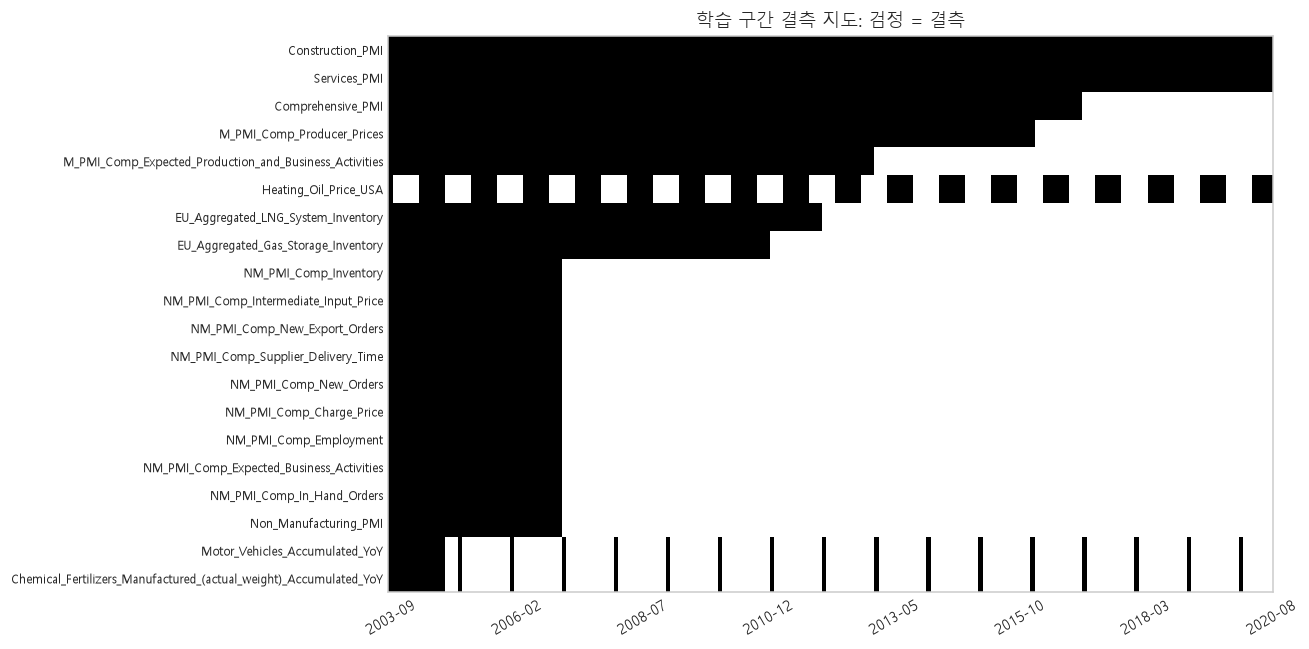

**관찰:** 학습 전체가 결측인 변수는 2개입니다. 이 변수는 학습 구간에서 효과를 추정할 수 없습니다. 시작 전 공백을 전체 평균으로 채우면 당시 없던 시계열을 존재했던 것처럼 다룰 수 있으므로 특징 채택과 결측 처리를 분리해야 합니다.

In [2]:
records = []
for col in train.columns.drop("date"):
    s = train[col]
    valid = s.dropna()
    first, last = s.first_valid_index(), s.last_valid_index()
    internal = int(s.loc[first:last].isna().sum()) if first is not None else 0
    pattern = ("학습 전체 결측" if valid.empty else
               "완전 관측" if not s.isna().any() else
               "시작 전 공백만" if first > 0 and last == len(s)-1 and internal == 0 else
               "끝부분 공백만" if first == 0 and last < len(s)-1 and internal == 0 else
               "복합/내부 공백")
    records.append({"변수": col, "train 결측%": s.isna().mean()*100,
                    "test 결측%": test[col].isna().mean()*100,
                    "첫 관측": train.loc[first, "date"] if first is not None else pd.NaT,
                    "마지막 관측": train.loc[last, "date"] if last is not None else pd.NaT,
                    "내부 결측 수": internal, "패턴": pattern})
missing = pd.DataFrame(records).set_index("변수").sort_values("train 결측%", ascending=False)
display(missing.head(20).round(2))
cols = missing.query("`train 결측%` > 0").head(20).index
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(train[cols].isna().T, aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1)
ax.set_yticks(range(len(cols)), cols, fontsize=8)
ticks = np.linspace(0, len(train)-1, 8, dtype=int)
ax.set_xticks(ticks, train.date.iloc[ticks].dt.strftime("%Y-%m"), rotation=30)
ax.set_title("학습 구간 결측 지도: 검정 = 결측")
ax.grid(False)
plt.tight_layout()
plt.show()
display(Markdown(f"**관찰:** 학습 전체가 결측인 변수는 {int((missing['train 결측%']==100).sum())}개입니다. "
                 "이 변수는 학습 구간에서 효과를 추정할 수 없습니다. 시작 전 공백을 전체 평균으로 채우면 "
                 "당시 없던 시계열을 존재했던 것처럼 다룰 수 있으므로 특징 채택과 결측 처리를 분리해야 합니다."))

## 2. 가격 수준과 변화율은 어떻게 다른가?

가격 수준의 분포와 월별 log return 분포, 큰 가격 변화가 발생한 월을 확인합니다. 극단값은 실제 가격 변동일 수 있으므로 자동 삭제하지 않습니다.

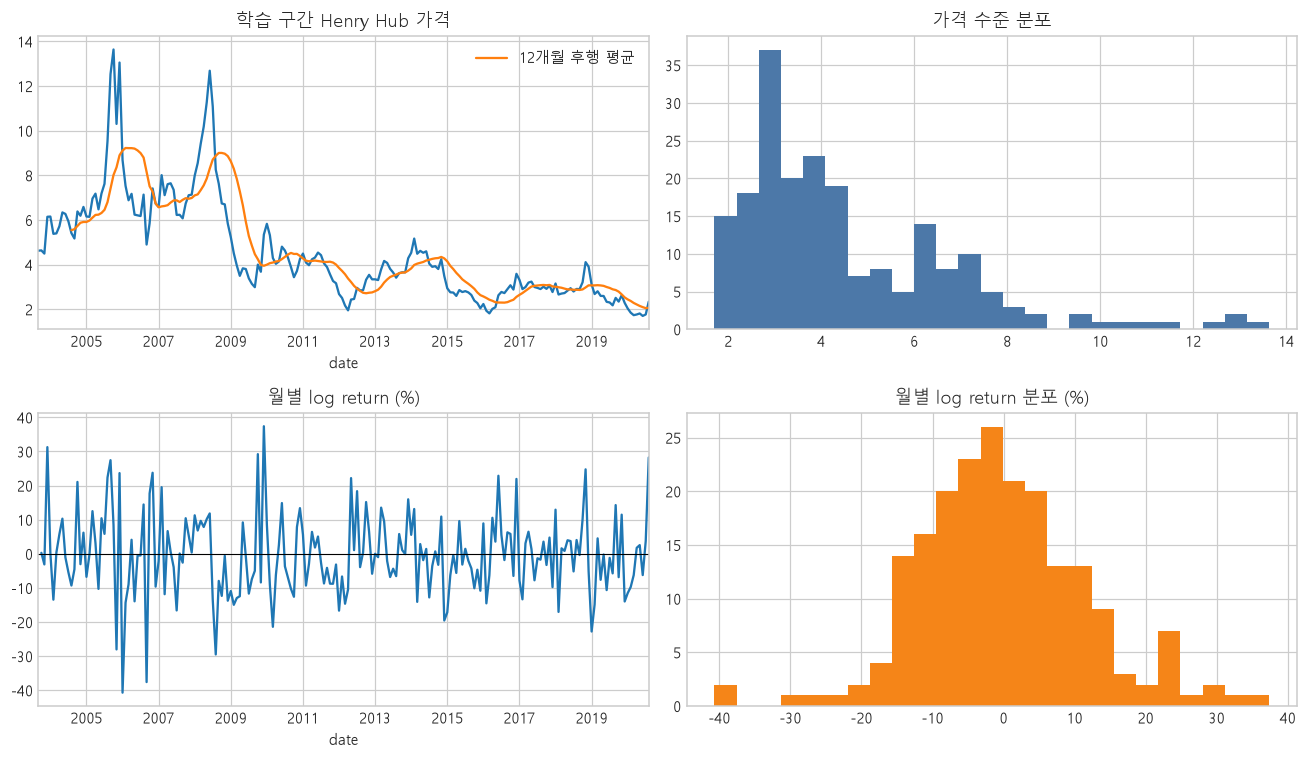

,가격,월별 log return
count,204.000000,203.000000
mean,4.539791,-0.003351
std,2.318997,0.118549
min,1.699550,-0.407114
25%,2.856243,-0.077946
50%,3.892380,-0.008255
75%,6.086317,0.062343
max,13.633800,0.373853


,가격,직전 가격,log return %
date,,,
2006-01-31,8.685,13.049,-40.711
2006-09-30,4.897,7.133,-37.605
2009-12-31,5.344,3.677,37.385
2003-12-31,6.140,4.492,31.260
2008-08-31,8.251,11.084,-29.508
2009-10-31,3.999,2.986,29.207
2020-08-31,2.340,1.765,28.233
2005-11-30,10.300,13.634,-28.036


**관찰:** 가격 범위는 1.700~13.634이며, 절대 월별 log return의 최댓값은 40.71%입니다. 가격과 수익률 타깃의 적합성을 비교할 이유는 있지만, 이 분포만으로 log return의 우월성을 결론내리지는 않습니다.

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
price.plot(ax=axes[0,0], title="학습 구간 Henry Hub 가격")
price.rolling(12).mean().plot(ax=axes[0,0], label="12개월 후행 평균", legend=True)
returns.mul(100).plot(ax=axes[1,0], title="월별 log return (%)")
axes[1,0].axhline(0, color="black", lw=0.7)
axes[0,1].hist(price, bins=25, color="#4C78A8")
axes[0,1].set_title("가격 수준 분포")
axes[1,1].hist(returns.dropna()*100, bins=25, color="#F58518")
axes[1,1].set_title("월별 log return 분포 (%)")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"가격": price.describe(), "월별 log return": returns.describe()}))
extremes = pd.DataFrame({"가격": price, "직전 가격": price.shift(1),
                         "log return %": returns*100})
display(extremes.loc[returns.abs().nlargest(8).index].round(3))
display(Markdown(f"**관찰:** 가격 범위는 {price.min():.3f}~{price.max():.3f}이며, "
                 f"절대 월별 log return의 최댓값은 {returns.abs().max()*100:.2f}%입니다. "
                 "가격과 수익률 타깃의 적합성을 비교할 이유는 있지만, 이 분포만으로 log return의 우월성을 결론내리지는 않습니다."))

## 3. 월별 계절성과 자기상관이 존재하는가?

월별 가격과 수익률을 별도로 봅니다. 월별 가격 평균은 장기 가격 수준 변화에도 영향을 받습니다. 수익률 자기상관과 가격 자기상관을 함께 비교해 단순 가격 지속성과 변화 방향의 예측 가능성을 구분합니다.

,n,price_mean,price_median,return_mean,return_std
month,,,,,
1,17,4.6134,4.4920,-0.0491,0.1417
2,17,4.4264,4.0921,-0.0620,0.1063
3,17,4.3055,3.9577,-0.0321,0.1012
4,17,4.4243,4.0329,0.0138,0.0717
5,17,4.5110,4.0744,0.0290,0.0825
6,17,4.6493,3.8060,0.0178,0.0890
7,17,4.4411,3.6430,-0.0258,0.0852
8,17,4.3533,3.4123,-0.0107,0.1312
9,17,4.4719,3.8900,-0.0114,0.1340


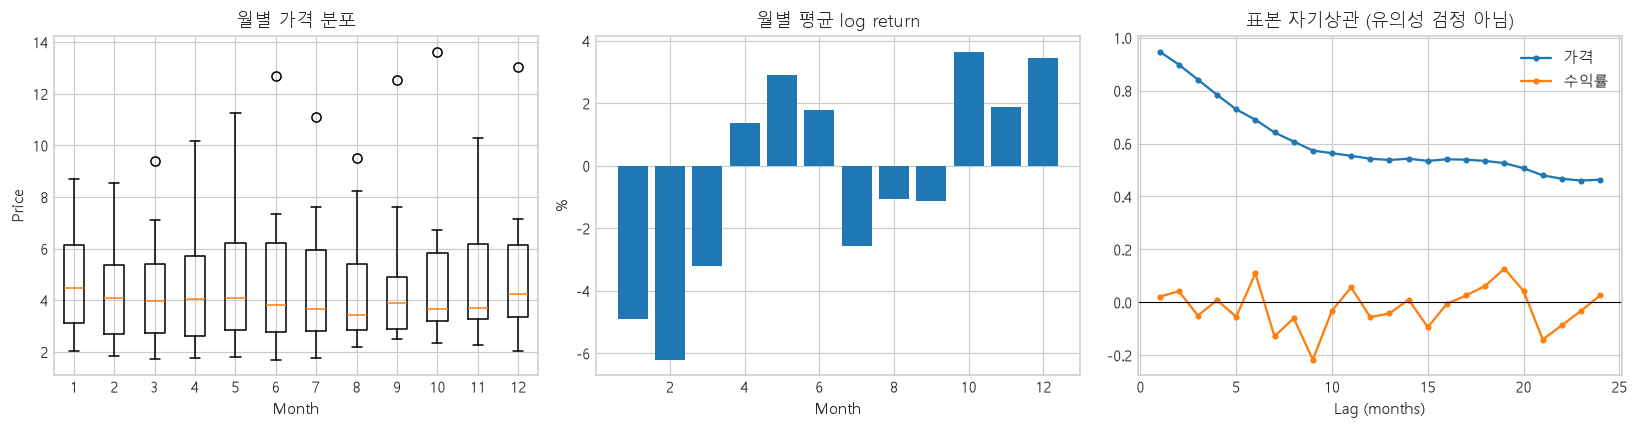

**관찰:** 1개월 자기상관은 가격 0.948, 수익률 0.021입니다. 가격 지속성이 크더라도 수익률 방향을 같은 정확도로 예측할 수 있다는 뜻은 아닙니다. 따라서 현재 가격 유지 예측을 필수 기준선으로 둡니다.

In [4]:
monthly = pd.DataFrame({"price": price, "return": returns, "month": price.index.month})
seasonality = monthly.groupby("month").agg(
    n=("price","count"), price_mean=("price","mean"), price_median=("price","median"),
    return_mean=("return","mean"), return_std=("return","std"))
display(seasonality.round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].boxplot([monthly.loc[monthly.month==m,"price"] for m in range(1,13)])
axes[0].set(title="월별 가격 분포", xlabel="Month", ylabel="Price")
axes[1].bar(seasonality.index, seasonality.return_mean*100)
axes[1].set(title="월별 평균 log return", xlabel="Month", ylabel="%")
acf = pd.DataFrame({"가격": [price.autocorr(l) for l in range(1,25)],
                    "수익률": [returns.autocorr(l) for l in range(1,25)]},
                   index=range(1,25))
acf.plot(ax=axes[2], marker="o", markersize=3)
axes[2].axhline(0, color="black", lw=.7)
axes[2].set(title="표본 자기상관 (유의성 검정 아님)", xlabel="Lag (months)")
plt.tight_layout()
plt.show()
display(Markdown(f"**관찰:** 1개월 자기상관은 가격 {acf.loc[1,'가격']:.3f}, "
                 f"수익률 {acf.loc[1,'수익률']:.3f}입니다. "
                 "가격 지속성이 크더라도 수익률 방향을 같은 정확도로 예측할 수 있다는 뜻은 아닙니다. "
                 "따라서 현재 가격 유지 예측을 필수 기준선으로 둡니다."))

## 4. 생산·저장·소비는 어떤 구조를 보이나?

서로 단위와 의미가 다른 원시값은 같은 축에 더하지 않습니다. 각 시계열을 별도 축에서 보고, 월별 평균 패턴도 각각 확인합니다. 저장은 재고(stock), 생산·소비는 기간 흐름(flow)이라는 차이가 있습니다.

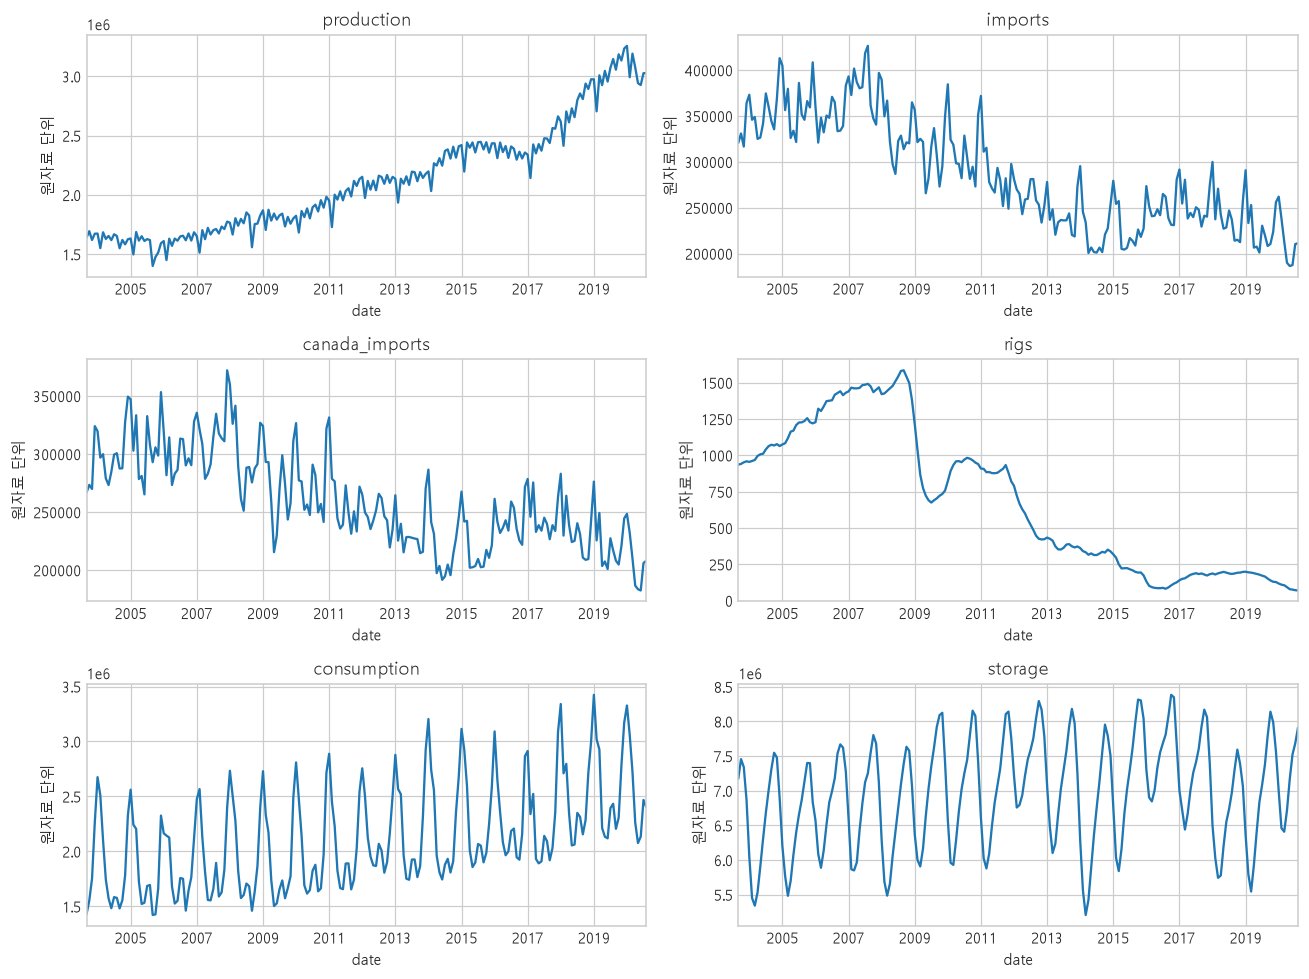

,production,imports,canada_imports,rigs,consumption,storage
date,,,,,,
1,2148062.94,328626.29,299806.94,691.00,2887808.24,6634787.06
2,1970722.94,289688.12,265450.94,683.29,2573741.76,6093272.94
3,2175978.24,298122.59,272658.76,669.24,2383054.71,5923377.06
4,2108850.59,269328.82,241448.88,665.12,1927975.29,6141752.35
5,2165402.35,267147.29,239121.94,663.47,1762602.94,6550615.29
6,2104463.53,265536.76,238117.18,663.24,1767481.18,6896107.06
7,2189287.06,291222.59,262310.00,666.18,1956418.24,7143475.88
8,2197433.53,286506.00,260171.12,672.88,1969832.35,7384441.18
9,2030840.59,274292.06,249402.18,724.06,1719418.24,7655886.47


**해석:** 생산·소비·저장의 수준, 변화량, 전년 동월 대비 변화는 다른 질문에 답합니다. Rig count는 생산과 별도 시차 관계를 검토할 후보입니다. 생산+수입−소비는 수출이 빠져 있어 실제 물질수지가 아닌 proxy입니다.

In [5]:
fund = train.set_index("date")[list(FUNDAMENTAL_COLUMNS.values())].rename(
    columns={v:k for k,v in FUNDAMENTAL_COLUMNS.items()})
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for col, ax in zip(fund, axes.flat):
    fund[col].plot(ax=ax, title=col)
    ax.set_ylabel("원자료 단위")
plt.tight_layout()
plt.show()
seasonal_fund = fund.groupby(fund.index.month).mean()
display(seasonal_fund.round(2))
display(Markdown("**해석:** 생산·소비·저장의 수준, 변화량, 전년 동월 대비 변화는 다른 질문에 답합니다. "
                 "Rig count는 생산과 별도 시차 관계를 검토할 후보입니다. "
                 "생산+수입−소비는 수출이 빠져 있어 실제 물질수지가 아닌 proxy입니다."))

## 5. 높은 수준 상관이 변화율에서도 유지되는가?

원자료의 동시점 Spearman 상관과 1개월 차분의 Spearman 상관을 비교합니다. 원자료의 발표 지연은 여기서 적용하지 않으므로 이 표는 구조 설명용입니다. 양수·음수·0이 섞일 수 있는 변수에도 동일 계산을 적용하도록 변화는 수익률 대신 차분으로 정의합니다.

,수준 상관,1개월 차분 상관,수준 표본수,차분 표본수
Total_Natural_Gas_Marketed_Production_USA,-0.845,-0.020,204,203
Natural_Gas_Imports_USA,0.759,0.011,204,203
Natural_Gas_Imports_From_Canada_USA,0.713,0.019,204,203
Natural_Gas_Rotary_Rig_Count_USA,0.881,0.062,204,203
Natural_Gas_Total_Consumption_USA,-0.421,0.075,204,203
Total_Natural_Gas_Underground_Storage_Volume_USA,-0.293,-0.016,204,203
BCOMNG_INDX,0.885,0.457,204,203
WTI_Crude_Oil,0.259,0.084,204,203
Brent_Crude_Oil,0.128,0.084,204,203
BCOMCL_INDX,0.857,0.131,204,203


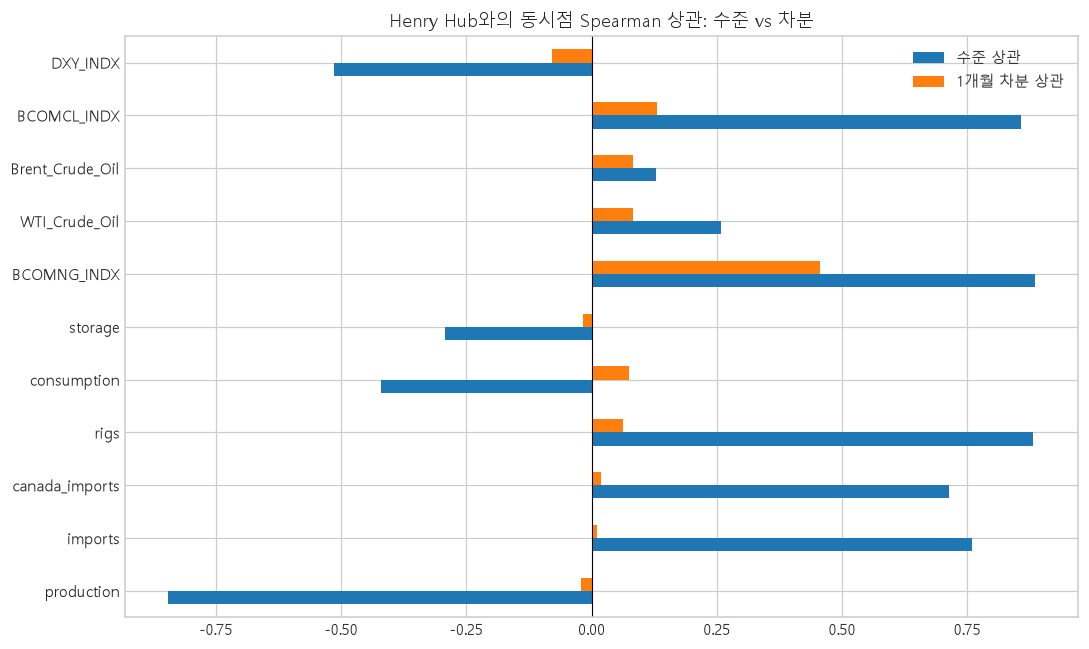

**해석:** 두 열의 부호와 크기가 다르면 수준 상관만으로 변수를 채택하면 안 됩니다. 공통 추세·계절성·변수 간 중복의 영향을 추가로 살펴야 합니다. 동시점 관계는 미래 예측의 증거도 아닙니다.

In [6]:
selected = list(FUNDAMENTAL_COLUMNS.values()) + ENERGY_COLUMNS
numeric = train[[TARGET, *selected]]
level_corr = numeric.corr(method="spearman", min_periods=36)[TARGET].drop(TARGET)
change_corr = numeric.diff().corr(method="spearman", min_periods=36)[TARGET].drop(TARGET)
comparison = pd.DataFrame({"수준 상관": level_corr, "1개월 차분 상관": change_corr,
                           "수준 표본수": numeric[selected].notna().sum(),
                           "차분 표본수": numeric[selected].diff().notna().sum()})
display(comparison.round(3))
comparison[["수준 상관","1개월 차분 상관"]].rename(
    index={v:k for k,v in FUNDAMENTAL_COLUMNS.items()}).plot.barh(figsize=(10,6))
plt.axvline(0, color="black", lw=.7)
plt.title("Henry Hub와의 동시점 Spearman 상관: 수준 vs 차분")
plt.tight_layout()
plt.show()
display(Markdown("**해석:** 두 열의 부호와 크기가 다르면 수준 상관만으로 변수를 채택하면 안 됩니다. "
                 "공통 추세·계절성·변수 간 중복의 영향을 추가로 살펴야 합니다. "
                 "동시점 관계는 미래 예측의 증거도 아닙니다."))

## 6. 실제 예측 시점에서 이용 가능한 특징과 미래 수익률의 관계

학습 코드의 `make_feature_matrix(..., 'conservative')`를 재사용합니다. 발표 지연과 후행 특징 처리는 실제 학습과 동일합니다. 지연 월수는 실제 release calendar를 확인한 값이 아니라 프로젝트의 명시적 가정입니다.

`t`의 특징과 `log(P[t+h]/P[t])`를 정렬합니다. 미래 가격은 분석 대상인 정답 열에만 들어갑니다. 전체 학습 구간의 상관을 보고 순위를 매기는 것은 탐색이며, 특징 선택의 독립 검증이 아닙니다.

,가정한 발표 지연(개월)
Total_Natural_Gas_Marketed_Production_USA,2
Natural_Gas_Imports_USA,2
Natural_Gas_Imports_From_Canada_USA,2
Natural_Gas_Rotary_Rig_Count_USA,0
Natural_Gas_Total_Consumption_USA,2
Total_Natural_Gas_Underground_Storage_Volume_USA,1
Kilian_Global_Economy_Index_WORLD,2
Fed_Fund_Effective_USA,0
Composite_Leading_Indicator_USA,2
Composite_Leading_Indicator_CHN,2


horizon,1,2,3
feature,,,
BCOMNG_INDX__return1,0.534,0.291,0.251
DXY_INDX__return1,-0.031,-0.056,-0.147
WTI_Crude_Oil__return1,0.100,0.154,0.213
consumption__yoy,0.052,0.074,0.031
fundamental_balance_equal_weight,-0.012,-0.054,-0.023
imports__yoy,0.103,0.113,0.153
price_log_return_1,0.089,0.103,0.041
price_log_return_3,0.045,0.030,0.014
production__yoy,-0.080,-0.051,-0.089


,feature,horizon,n,spearman
10,BCOMNG_INDX__return1,1,202,0.533919
34,storage_seasonal_deviation,3,176,0.296469
24,BCOMNG_INDX__return1,2,201,0.291249
38,BCOMNG_INDX__return1,3,200,0.250623
20,storage_seasonal_deviation,2,177,0.234910
39,WTI_Crude_Oil__return1,3,200,0.213001
6,storage_seasonal_deviation,1,178,0.163145
25,WTI_Crude_Oil__return1,2,201,0.153569
31,imports__yoy,3,187,0.152645
40,DXY_INDX__return1,3,200,-0.146687


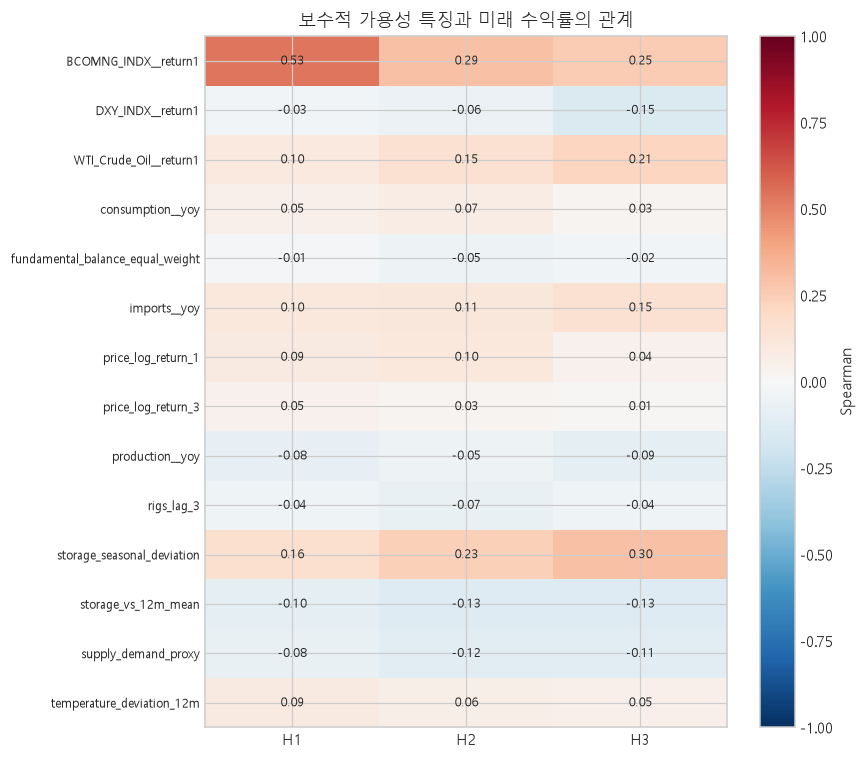

**해석:** horizon별 관계와 유효 표본수가 다릅니다. 여러 변수 중 큰 상관만 고르면 우연한 관계를 선택할 수 있고, H2/H3 정답은 서로 겹쳐 독립 표본도 아닙니다. 이 결과는 검증할 가설 목록이며 채택 여부는 rolling-origin ablation에서 판단합니다.

In [7]:
display(pd.Series(CONSERVATIVE_RELEASE_LAGS, name="가정한 발표 지연(개월)").to_frame())
features, groups = make_feature_matrix(train, "conservative")
candidate_features = [
    "price_log_return_1", "price_log_return_3", "production__yoy", "imports__yoy",
    "rigs_lag_3", "storage_vs_12m_mean", "storage_seasonal_deviation",
    "consumption__yoy", "supply_demand_proxy", "fundamental_balance_equal_weight",
    "BCOMNG_INDX__return1", "WTI_Crude_Oil__return1", "DXY_INDX__return1",
    "temperature_deviation_12m"]
rows = []
for h in [1,2,3]:
    y = make_horizon_targets(train,h)["log_return"]
    for feature in candidate_features:
        paired = pd.concat([features[feature].rename("x"), y.rename("y")], axis=1).dropna()
        rows.append({"feature": feature, "horizon": h, "n": len(paired),
                     "spearman": paired.x.corr(paired.y,method="spearman") if len(paired)>=36 else np.nan})
relationships = pd.DataFrame(rows)
corr_table = relationships.pivot(index="feature",columns="horizon",values="spearman")
display(corr_table.round(3))
display(relationships.sort_values("spearman",key=lambda s:s.abs(),ascending=False).head(10))
fig, ax = plt.subplots(figsize=(8,7))
im = ax.imshow(corr_table, cmap="RdBu_r",vmin=-1,vmax=1,aspect="auto")
ax.set_yticks(range(len(corr_table)),corr_table.index,fontsize=8)
ax.set_xticks([0,1,2],["H1","H2","H3"])
for i in range(len(corr_table)):
    for j in range(3):
        ax.text(j,i,f"{corr_table.iloc[i,j]:.2f}",ha="center",va="center",fontsize=8)
fig.colorbar(im, ax=ax, label="Spearman")
ax.set_title("보수적 가용성 특징과 미래 수익률의 관계")
plt.tight_layout()
plt.show()
display(Markdown("**해석:** horizon별 관계와 유효 표본수가 다릅니다. 여러 변수 중 큰 상관만 고르면 "
                 "우연한 관계를 선택할 수 있고, H2/H3 정답은 서로 겹쳐 독립 표본도 아닙니다. "
                 "이 결과는 검증할 가설 목록이며 채택 여부는 rolling-origin ablation에서 판단합니다."))

## 7. Ridge를 선택한 근거가 검증 결과에도 있는가?

소표본·관련 특징이 많은 상황에서 Ridge는 계수 크기를 억제하는 후보입니다. 그러나 최종 선택은 동일 원점의 성능 비교가 필요합니다. 아래는 `outputs/`에 저장된 보수 모드 결과를 읽어 확인합니다. 노트북에서 모델을 재학습하거나 제출 파일을 변경하지 않습니다.

**결과 출처:** 가용성 모드 conservative, 검증 시작 2013-09-30.

horizon,1,2,3
feature_group,,,
E1_history,7.848,11.250,15.218
E2_fundamentals,7.753,9.738,13.285
E3_energy,7.190,9.461,13.560
E4_macro,7.322,10.341,14.490
E5_external,7.720,11.718,15.220


horizon,1,2,3
model,,,
elastic_net_log_return,6.827,9.477,13.957
last_value_naive,7.666,10.480,13.570
lightgbm_log_return,7.181,9.813,14.862
ridge_log_return,7.190,9.461,13.285
ridge_raw_price,13.439,14.483,15.099
seasonal_naive,27.208,27.428,27.729


,horizon,feature_group,model,validation_mape_pct,validation_mae,direction_accuracy_pct,turning_f1_pct
0,1,E3_energy,elastic_net_log_return,6.827213,0.205197,66.265060,67.441860
1,2,E3_energy,ridge_log_return,9.461256,0.280198,58.536585,56.410256
2,3,E2_fundamentals,ridge_log_return,13.284618,0.405438,61.728395,60.759494


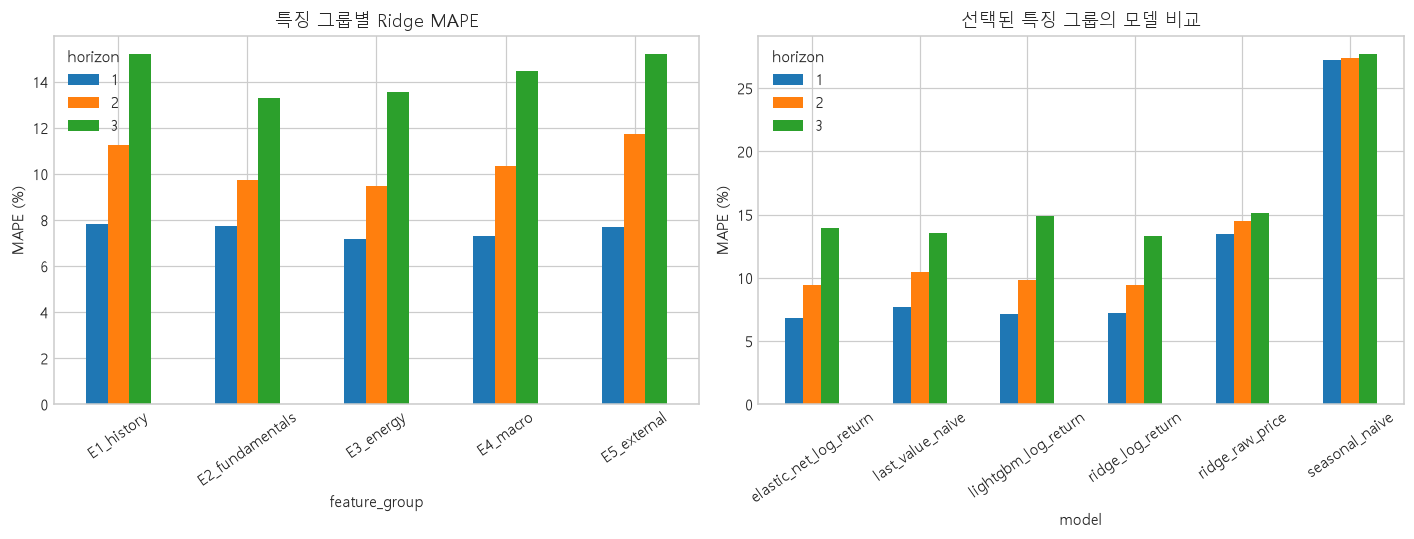

**해석:** H3 Ridge 선택 근거는 후보 비교 결과입니다. 기존 alpha=10은 고정 설정이며 최적성을 검증한 값이 아닙니다. 이 구간으로 특징과 모델을 선택했으므로 수치는 선택 편향을 포함할 수 있습니다. 별도 기간 또는 중첩 시계열 검증이 다음 단계입니다.

In [8]:
import json
output_dir = ROOT / "outputs"
summary = json.loads((output_dir / "run_summary.json").read_text(encoding="utf-8"))
assert summary["availability_mode"] == "conservative"
metrics = pd.read_csv(output_dir / "experiment_metrics.csv")
ablation = metrics.loc[metrics.stage=="ablation"]
models = metrics.loc[metrics.stage=="model_comparison"]
display(Markdown(f"**결과 출처:** 가용성 모드 {summary['availability_mode']}, "
                 f"검증 시작 {summary['first_validation_origin']}."))
display(ablation.pivot(index="feature_group",columns="horizon",values="mape_pct").round(3))
display(models.pivot(index="model",columns="horizon",values="mape_pct").round(3))
display(pd.read_csv(output_dir / "model_selection.csv"))
fig, axes = plt.subplots(1,2,figsize=(13,5))
ablation.pivot(index="feature_group",columns="horizon",values="mape_pct").plot.bar(ax=axes[0])
models.pivot(index="model",columns="horizon",values="mape_pct").plot.bar(ax=axes[1])
for ax,title in zip(axes,["특징 그룹별 Ridge MAPE","선택된 특징 그룹의 모델 비교"]):
    ax.set(title=title,ylabel="MAPE (%)")
    ax.tick_params(axis="x",rotation=35)
plt.tight_layout()
plt.show()
display(Markdown("**해석:** H3 Ridge 선택 근거는 후보 비교 결과입니다. "
                 "기존 alpha=10은 고정 설정이며 최적성을 검증한 값이 아닙니다. "
                 "이 구간으로 특징과 모델을 선택했으므로 수치는 선택 편향을 포함할 수 있습니다. "
                 "별도 기간 또는 중첩 시계열 검증이 다음 단계입니다."))

## 8. 왜 현재 가격과 0.5씩 섞었고, 어떤 결과가 나왔나?

`예측 = 현재 가격 + 0.5 × (Ridge 예측 − 현재 가격)`입니다. 현재 가격은 Last Value Naive라는 강한 기준선이며, 0.5는 변화를 절반으로 축소하는 고정 실험 기준입니다. 두 예측의 신뢰도가 같거나 최적 가중치라는 주장은 아닙니다. 기존 검증 예측에서 직접 다시 계산합니다.

,horizon,feature_group,model,validation_year,mape_pct,mae,direction_accuracy_pct,n_origins,turning_precision_pct,turning_recall_pct,turning_f1_pct,actual_turning_points,predicted_turning_points
0,3,E2_fundamentals,ridge_log_return,all,13.2846,0.4054,61.7284,81,61.5385,60.0,60.7595,40,39
9,3,E2_fundamentals,last_value_naive,all,13.5698,0.3914,0.0000,81,0.0000,0.0,0.0000,40,0
18,3,E2_fundamentals,ridge_naive_equal_blend,all,12.4128,0.3616,61.7284,81,61.5385,60.0,60.7595,40,39


model,last_value_naive,ridge_log_return,ridge_naive_equal_blend
validation_year,,,
2013,17.160,28.162,22.661
2014,16.893,18.684,13.218
2015,11.590,14.465,12.487
2016,14.311,8.583,10.805
2017,6.192,8.680,7.098
2018,16.694,13.061,14.465
2019,16.690,12.214,14.114
2020,8.412,11.034,9.710


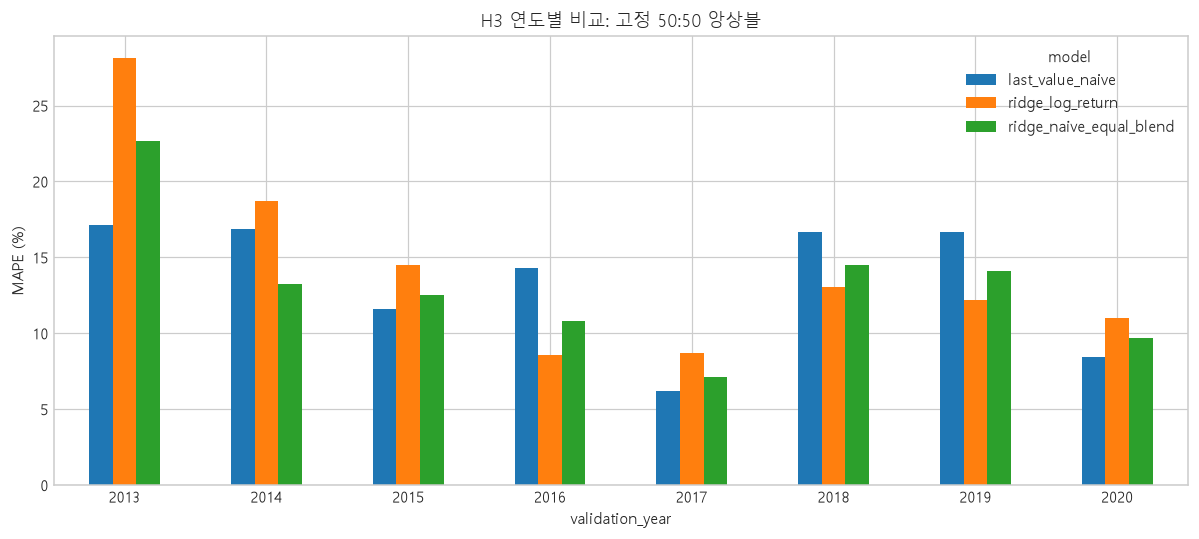

**관찰:** 앙상블은 8개 연도 중 Ridge 대비 5개, Naive 대비 4개에서 개선됩니다. 항상 더 좋지는 않습니다. 현재 가격 쪽으로 양의 비율만큼 축소하므로 Ridge의 예측 방향과 반전 판정은 그대로입니다.

In [9]:
from src.ensemble import evaluate_ensemble
backtests = pd.read_csv(output_dir / "backtest_predictions.csv")
ensemble_predictions, ensemble_metrics = evaluate_ensemble(backtests)
display(ensemble_metrics.loc[ensemble_metrics.validation_year=="all"].round(4))
yearly = ensemble_metrics.loc[ensemble_metrics.validation_year!="all"].pivot(
    index="validation_year",columns="model",values="mape_pct")
display(yearly.round(3))
yearly.plot.bar(figsize=(11,5))
plt.ylabel("MAPE (%)")
plt.title("H3 연도별 비교: 고정 50:50 앙상블")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
ridge_wins = int((yearly.ridge_naive_equal_blend < yearly.ridge_log_return).sum())
naive_wins = int((yearly.ridge_naive_equal_blend < yearly.last_value_naive).sum())
display(Markdown(f"**관찰:** 앙상블은 {len(yearly)}개 연도 중 Ridge 대비 {ridge_wins}개, "
                 f"Naive 대비 {naive_wins}개에서 개선됩니다. "
                 "항상 더 좋지는 않습니다. 현재 가격 쪽으로 양의 비율만큼 축소하므로 "
                 "Ridge의 예측 방향과 반전 판정은 그대로입니다."))


## 분석에서 결정으로 이어지는 결론

| 확인한 내용 | 현재 판단 | 추가로 필요한 검증 |
|---|---|---|
| 결측 위치와 시계열 시작 시점 | 학습 전체 결측·초기 공백·내부 공백을 구분 | 원자료의 수집·발표 이유 확인 |
| 가격 수준과 변화 분포 | raw price와 log return을 별도 후보로 비교 | 동일 원점 예측 오차 비교 |
| 계절성과 가격 지속성 | 월 특징과 Naive를 포함할 근거 | 연도별·시기별 안정성 |
| 수준·차분·미래 수익률 상관 | 탐색 가설로 사용 | ablation 및 발표일 확인 |
| H3 Ridge 선택 | 기존 후보 비교에서 선택 | 규제 강도 선택을 포함한 중첩 검증 |
| 고정 50:50 앙상블 | 기존 검증에서 개선된 후속 후보 | 과거 구간에서 가중치 선택 후 별도 미래 구간 평가 |

**이 노트북은 새로운 성능을 주장하거나 인과관계를 증명하지 않습니다.** 실제 데이터와 저장된 실험을 근거로 무엇을 관찰했고, 어떤 모델링 판단을 내렸으며, 어디까지 미검증인지 설명합니다.